In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

DATA_PATH = "../dataset/house_price_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum())

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

for col in numeric_cols:
    if col not in ["House_ID", "Price"]:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())


Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277.0
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512.0
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806.0
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776.0
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975.0



Missing values:
 House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64
House_ID                      0
Area_sqft                     0
Bedrooms                      0
Bathrooms                     0
Floors                        0
Year_Built                    0
Location                      0
Furnishing_Status             0
Parking_Available             0
Garage_Count                  0
Lot_Size_sqft      

In [8]:
X = df.drop(columns=["House_ID", "Price"])

print("Independent variables:")
display(X.head())

print("Number of features:", X.shape[1])

Independent variables:


,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated
0,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no
1,2646.2,2.0,5.0,2.0,2005,riverside,Semi Furnished,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y
2,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,6.48,Yes,no
3,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes
4,3227.0,3.0,5.0,2.0,1995,Lake side,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes


Number of features: 16


In [9]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical Features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [10]:
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_processed = preprocessor.fit_transform(X)

if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Shape before PCA:", X_processed.shape)

Shape before PCA: (15025, 80)


In [11]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_processed)

print("Shape after PCA:", X_pca.shape)
print("Number of Principal Components:", pca.n_components_)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())

Shape after PCA: (15025, 53)
Number of Principal Components: 53
Explained Variance Ratio: [0.06814843 0.06715354 0.06695924 0.06654024 0.06610321 0.06594664
 0.06551545 0.06484791 0.06398831 0.06365504 0.0177087  0.0173363
 0.01649013 0.01630229 0.01233574 0.01091648 0.01031398 0.01026658
 0.00942994 0.00925802 0.00831969 0.00795538 0.00733398 0.00715303
 0.00656369 0.0065125  0.00615173 0.00600795 0.00579951 0.00565562
 0.00561643 0.00552765 0.00548169 0.00544386 0.00531047 0.00485948
 0.00480829 0.00470624 0.00469807 0.00466474 0.00457963 0.00450202
 0.0044551  0.004343   0.00411029 0.00321463 0.00313306 0.00270462
 0.00269298 0.00267247 0.0026664  0.00266247 0.00264989]
Total Explained Variance: 0.9521727297905569


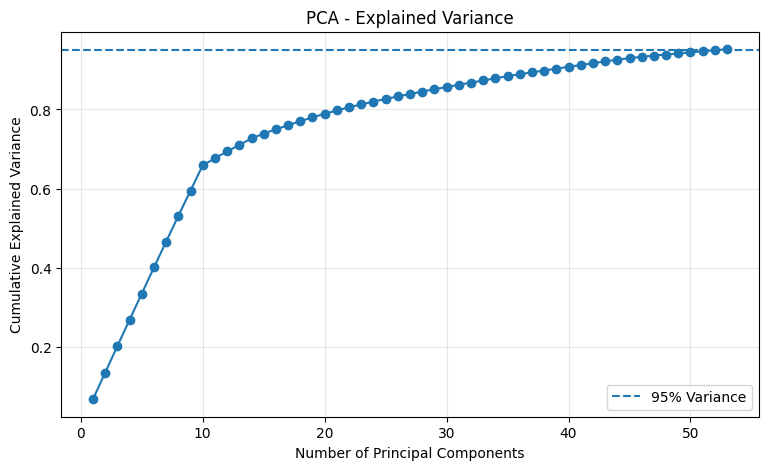

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.axhline(y=0.95, linestyle="--", label="95% Variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

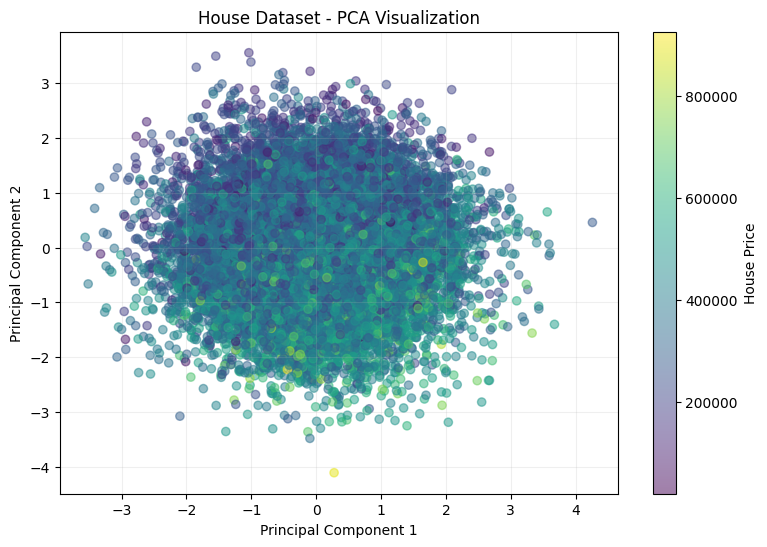

In [13]:
pca_2d = PCA(n_components=2)

X_2d = pca_2d.fit_transform(X_processed)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=df["Price"],
    cmap="viridis",
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("House Dataset - PCA Visualization")

plt.colorbar(scatter, label="House Price")

plt.grid(alpha=0.2)
plt.show()

In [14]:
print("Original Number of Features:", X_processed.shape[1])
print("Reduced Number of Features:", X_pca.shape[1])

reduction = (
    1 - X_pca.shape[1] / X_processed.shape[1]
) * 100

print("Dimensionality Reduction:", round(reduction, 2), "%")

Original Number of Features: 80
Reduced Number of Features: 53
Dimensionality Reduction: 33.75 %
